# Initial Data Exploration

In [1]:
import pandas as pd
import numpy as np

df_items = pd.read_csv(
    "../data/raw/olist_order_items_dataset.csv",
    dtype={
        "order_id": "string",
        "product_id": "string",
        "seller_id": "string"
    }
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
print("Shape:", df_items.shape)
display(df_items.head())

Shape: (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [3]:
df_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  string 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  string 
 3   seller_id            112650 non-null  string 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(1), string(3)
memory usage: 6.0+ MB


In [4]:
display(df_items.isnull().sum())

order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

In [5]:
display(df_items.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,112650,98666,8272b63d03f5f79c56e9e4120aec44ef,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_item_id,112650.0,NaN,NaN,NaN,1.197834,0.705124,1.0,1.0,1.0,1.0,21.0
product_id,112650,32951,aca2eb7d00ea1a7b8ebd4e68314663af,527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
seller_id,112650,3095,6560211a19b47992c3666cc44a7e94c0,2033,NaN,NaN,NaN,NaN,NaN,NaN,NaN
shipping_limit_date,112650,93318,2017-07-21 18:25:23,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,112650.0,NaN,NaN,NaN,120.653739,183.633928,0.85,39.9,74.99,134.9,6735.0
freight_value,112650.0,NaN,NaN,NaN,19.99032,15.806405,0.0,13.08,16.26,21.15,409.68


In [6]:
print("Duplicate rows:", df_items.duplicated().sum())

Duplicate rows: 0


# Check duplicates and item distribution

In [7]:
print("Exact duplicate rows:", df_items.duplicated().sum())

print(
    "Duplicate order-item combinations:",
    df_items.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

Exact duplicate rows: 0
Duplicate order-item combinations: 0


In [9]:
# rders containing multiple items
items_per_order = (
    df_items.groupby("order_id")
    .size()
    .reset_index(name="total_items")
)

print("Total unique orders:", len(items_per_order))
print("Orders with multiple items:",
      (items_per_order["total_items"] > 1).sum())

display(
    items_per_order["total_items"]
    .value_counts()
    .sort_index()
    .head(10)
)

Total unique orders: 98666
Orders with multiple items: 9803


total_items
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
Name: count, dtype: int64

### Order Items – Initial Data Quality Findings

1. Total item records: 112,650.
2. Unique orders: 98,666.
3. Exact duplicate rows: 0.
4. Duplicate order-item combinations: 0.
5. Single-item orders: 88,863.
6. Multiple-item orders: 9,803.

Business observation:
Most orders contain a single item, while a smaller proportion
contain multiple products.

### How many products were sold?

In [10]:
product_summary = df_items.groupby("product_id").agg(
    total_units_sold=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

print("Unique products sold:", product_summary["product_id"].nunique())
print("Total units sold:", product_summary["total_units_sold"].sum())

print("\nTop 10 products by units sold:")
display(
    product_summary.sort_values(
        "total_units_sold", ascending=False
    ).head(10)
)

Unique products sold: 32951
Total units sold: 112650

Top 10 products by units sold:


,product_id,total_units_sold,total_orders,total_revenue
22112,aca2eb7d00ea1a7b8ebd4e68314663af,527,431,37608.90
19742,99a4788cb24856965c36a24e339b6058,488,467,43025.56
8613,422879e10f46682990de24d770e7f83d,484,352,26577.22
7364,389d119b48cf3043d311335e499d9c6b,392,311,21440.59
7079,368c6c730842d78016ad823897a372db,388,291,21056.80
10840,53759a2ecddad2bb87a079a1f1519f73,373,287,20387.20
27039,d1c427060a0f73f6b889a5c7c61f2ac4,343,323,47214.51
10867,53b36df67ebb7c41585e8d54d6772e08,323,306,37683.42
2794,154e7e31ebfa092203795c972e5804a6,281,269,6325.19
8051,3dd2a17168ec895c781a9191c1e95ad7,274,255,41082.60


### Product Sales Analysis – Key Findings

1. Unique products sold: 32,951.
2. Total units sold: 112,650.
3. Highest-selling product: 527 units.
4. Top product by revenue among the top 10: R$47,214.51.

Business observation:
Product sales volume and revenue contribution differ.
High sales quantity does not necessarily mean high revenue.

#### Orders Containing Multiple Items

In [11]:
print(
    "Average items per order:",
    round(items_per_order["total_items"].mean(), 2)
)

print(
    "Median items per order:",
    items_per_order["total_items"].median()
)

print(
    "Maximum items in one order:",
    items_per_order["total_items"].max()
)

print("\nTop 10 orders by item count:")

display(
    items_per_order.sort_values(
        "total_items", ascending=False
    ).head(10)
)

Average items per order: 1.14
Median items per order: 1.0
Maximum items in one order: 21

Top 10 orders by item count:


,order_id,total_items
50137,8272b63d03f5f79c56e9e4120aec44ef,21
10459,1b15974a0141d54e36626dca3fdc731a,20
65715,ab14fdcfbe524636d65ee38360e22ce8,20
60941,9ef13efd6949e4573a18964dd1bbe7f5,15
25583,428a2f660dc84138d969ccd69a0ab6d5,15
59688,9bdc4d4c71aa1de4606060929dee888c,14
44594,73c8ab38f07dc94389065f7eba4f297a,14
21484,37ee401157a3a0b28c9c6d0ed8c3b24b,13
67424,af822dacd6f5cff7376413c03a388bb7,12
22378,3a213fcdfe7d98be74ea0dc05a8b31ae,12


### Multiple Items per Order – Key Findings

1. Average items per order: 1.14.
2. Median items per order: 1.
3. Maximum items in one order: 21.
4. Multiple-item orders: 9,803.

Business observation:
Most orders contain a single item.
Cross-selling and product bundling could help increase
the average number of items per order.

In [12]:
top_products_revenue = (
    product_summary
    .sort_values("total_revenue", ascending=False)
    .head(10)
)

display(top_products_revenue)

,product_id,total_units_sold,total_orders,total_revenue
24086,bb50f2e236e5eea0100680137654686c,195,187,63885.00
14068,6cdd53843498f92890544667809f1595,156,151,54730.20
27613,d6160fb7873f184099d9bc95e30376af,35,35,48899.34
27039,d1c427060a0f73f6b889a5c7c61f2ac4,343,323,47214.51
19742,99a4788cb24856965c36a24e339b6058,488,467,43025.56
8051,3dd2a17168ec895c781a9191c1e95ad7,274,255,41082.60
4996,25c38557cf793876c5abdd5931f922db,38,38,38907.32
12351,5f504b3a1c75b73d6151be81eb05bdc9,63,63,37733.90
10867,53b36df67ebb7c41585e8d54d6772e08,323,306,37683.42
22112,aca2eb7d00ea1a7b8ebd4e68314663af,527,431,37608.90


### Top-Selling Products by Revenue – Key Findings

- Highest revenue product: R$63,885.00.
- Units sold by this product: 195.
- Top-selling product by quantity: 527 units.
- Revenue from the highest-volume product: R$37,608.90.

Business observation:
Product sales volume and revenue contribution differ.
Some products generate higher revenue despite lower sales quantities.

### Top-Performing Sellers

In [13]:
seller_summary = df_items.groupby("seller_id").agg(
    total_units_sold=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price", "sum")
).reset_index()

top_sellers_revenue = seller_summary.sort_values(
    "total_revenue", ascending=False
).head(10)

display(top_sellers_revenue)

,seller_id,total_units_sold,total_orders,total_revenue
857,4869f7a5dfa277a7dca6462dcf3b52b2,1156,1132,229472.63
1013,53243585a1d6dc2643021fd1853d8905,410,358,222776.05
881,4a3ca9315b744ce9f8e9374361493884,1987,1806,200472.92
3024,fa1c13f2614d7b5c4749cbc52fecda94,586,585,194042.03
1535,7c67e1448b00f6e969d365cea6b010ab,1364,982,187923.89
1560,7e93a43ef30c4f03f38b393420bc753a,340,336,176431.87
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,1314,160236.57
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,1160,141745.53
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,915,138968.55
1824,955fee9216a65b617aa5c0531780ce60,1499,1287,135171.70


### Top-Performing Sellers – Key Findings

1. Highest revenue seller: R$229,472.63.
2. Units sold by top seller: 1,156.
3. Orders handled: 1,132.
4. Third-ranked seller sold 1,987 items but generated less revenue.

Business observation:
Seller sales volume and revenue contribution differ.
Both metrics should be considered when evaluating seller performance.

### Product Quantity Distribution

In [14]:
quantity_distribution = (
    df_items.groupby("order_id")
    .size()
    .value_counts()
    .sort_index()
    .reset_index()
)

quantity_distribution.columns = [
    "items_per_order",
    "number_of_orders"
]

quantity_distribution["percentage"] = (
    quantity_distribution["number_of_orders"] /
    quantity_distribution["number_of_orders"].sum() * 100
).round(2)

display(quantity_distribution)

,items_per_order,number_of_orders,percentage
0,1,88863,90.06
1,2,7516,7.62
2,3,1322,1.34
3,4,505,0.51
4,5,204,0.21
5,6,198,0.20
6,7,22,0.02
7,8,8,0.01
8,9,3,0.00
9,10,8,0.01


### Product Quantity Distribution – Key Findings

1. Single-item orders: 88,863 (90.06%).
2. Two-item orders: 7,516 (7.62%).
3. Three-item orders: 1,322 (1.34%).
4. Orders containing six or more items: 256 (0.26%).
5. Maximum items in one order: 21.

Business observation:
The majority of customers purchase one item per order.
Product bundling and cross-selling could help increase basket size.

### Product Price Distribution

In [15]:
print("Average price:", round(df_items["price"].mean(), 2))
print("Median price:", round(df_items["price"].median(), 2))
print("Minimum price:", df_items["price"].min())
print("Maximum price:", df_items["price"].max())

display(df_items["price"].describe())

Average price: 120.65
Median price: 74.99
Minimum price: 0.85
Maximum price: 6735.0


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

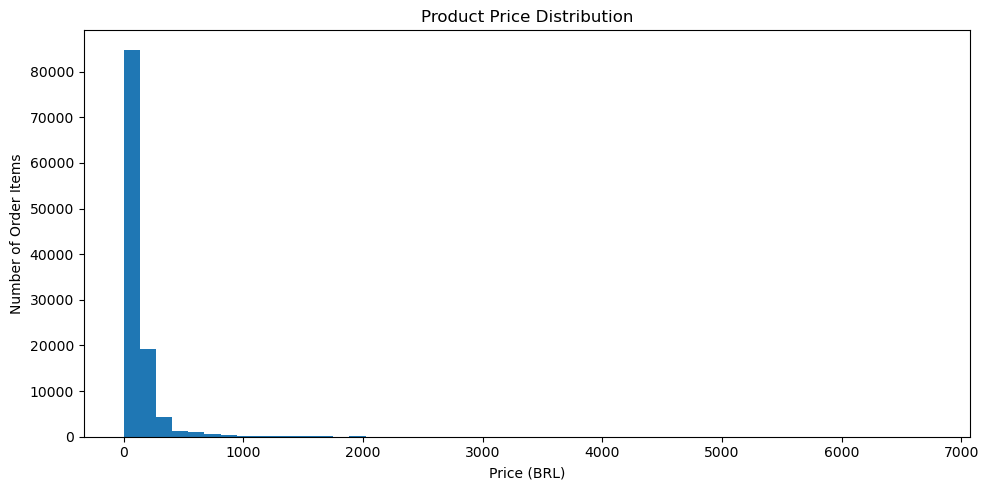

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df_items["price"], bins=50)
plt.title("Product Price Distribution")
plt.xlabel("Price (BRL)")
plt.ylabel("Number of Order Items")
plt.tight_layout()
plt.show()

- Average product price: R$120.65.
- Median product price: R$74.99.
- Minimum price: R$0.85.
- Maximum price: R$6,735.00.
- 50% of order items have prices between R$39.90 and R$134.90.

**Insight:** Product prices are right-skewed. The average is higher than the median because a small number of expensive products influence the overall average. High-value records should be investigated before deciding whether they are outliers.

### Freight Cost Analysis

In [17]:
print("Average freight:", round(df_items["freight_value"].mean(), 2))
print("Median freight:", round(df_items["freight_value"].median(), 2))
print("Minimum freight:", df_items["freight_value"].min())
print("Maximum freight:", df_items["freight_value"].max())

display(df_items["freight_value"].describe())

Average freight: 19.99
Median freight: 16.26
Minimum freight: 0.0
Maximum freight: 409.68


count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

- Average freight: R$19.99.
- Median freight: R$16.26.
- Minimum freight: R$0.00.
- Maximum freight: R$409.68.
- 50% of freight charges fall between R$13.08 and R$21.15.

**Insight:** Freight costs are right-skewed. A small number of high-freight records increase the average. Zero-freight and unusually expensive shipments should be investigated during further analysis.

### Revenue Contribution by Seller

In [18]:
seller_revenue = (
    df_items.groupby("seller_id")["price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(seller_revenue)

seller_id
4869f7a5dfa277a7dca6462dcf3b52b2    229472.63
53243585a1d6dc2643021fd1853d8905    222776.05
4a3ca9315b744ce9f8e9374361493884    200472.92
fa1c13f2614d7b5c4749cbc52fecda94    194042.03
7c67e1448b00f6e969d365cea6b010ab    187923.89
7e93a43ef30c4f03f38b393420bc753a    176431.87
da8622b14eb17ae2831f4ac5b9dab84a    160236.57
7a67c85e85bb2ce8582c35f2203ad736    141745.53
1025f0e2d44d7041d6cf58b6550e0bfa    138968.55
955fee9216a65b617aa5c0531780ce60    135171.70
Name: price, dtype: float64

- Top revenue-generating seller: 4869f7a5dfa277a7dca6462dcf3b52b2.
- Revenue generated: R$229,472.63.
- The top five sellers each generated more than R$187,000.
- Revenue is calculated by summing product prices for each seller.
- Freight charges are excluded.

**Insight:** Seller revenue is concentrated among a group of high-performing sellers. Seller-level revenue analysis can help identify important contributors to marketplace sales.

### Order Item Value Analysis

In [19]:
order_value = (
    df_items.groupby("order_id")
    .agg(
        total_order_value=("price", "sum"),
        total_items=("order_item_id", "count")
    )
    .reset_index()
)

display(order_value["total_order_value"].describe())

count    98666.000000
mean       137.754076
std        210.645145
min          0.850000
25%         45.900000
50%         86.900000
75%        149.900000
max      13440.000000
Name: total_order_value, dtype: float64

- Total orders: 98,666.
- Average order value: R$137.75.
- Median order value: R$86.90.
- Minimum order value: R$0.85.
- Maximum order value: R$13,440.00.
- 50% of orders have product values between R$45.90 and R$149.90.

**Insight:** The order value distribution is right-skewed. A small number of high-value orders increase the average above the median. These values represent product revenue and exclude freight charges.

### Shipping Cost as a Percentage of Product Price

In [20]:
df_items["freight_percentage"] = (
    df_items["freight_value"] / df_items["price"]
) * 100

display(df_items["freight_percentage"].describe())

count    112650.000000
mean         32.086355
std          34.989368
min           0.000000
25%          13.403366
50%          23.135624
75%          39.303621
max        2623.529412
Name: freight_percentage, dtype: float64

- Average freight percentage: 32.09%.
- Median freight percentage: 23.14%.
- Minimum: 0%.
- Maximum: 2,623.53%.
- 50% of order items have freight percentages between 13.40% and 39.30%.

**Insight:** Freight represents a substantial cost relative to product prices. Some low-priced products have disproportionately high freight charges. Extreme values should be investigated before drawing business conclusions.

# Data Cleaning

In [21]:
df_items_clean = df_items.copy()

df_items_clean["shipping_limit_date"] = pd.to_datetime(
    df_items_clean["shipping_limit_date"],
    errors="coerce"
)

print(df_items_clean.info())
print("Missing shipping dates:", df_items_clean["shipping_limit_date"].isna().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  string        
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  string        
 3   seller_id            112650 non-null  string        
 4   shipping_limit_date  112650 non-null  datetime64[ns]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
 7   freight_percentage   112650 non-null  float64       
dtypes: datetime64[ns](1), float64(3), int64(1), string(3)
memory usage: 6.9 MB
None
Missing shipping dates: 0


In [22]:
print("Zero prices:", (df_items_clean["price"] == 0).sum())
print("Negative prices:", (df_items_clean["price"] < 0).sum())

print("\nPrice distribution:")
display(df_items_clean["price"].describe())

print("Prices above R$1,000:",
      (df_items_clean["price"] > 1000).sum())

Zero prices: 0
Negative prices: 0

Price distribution:


count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
max        6735.000000
Name: price, dtype: float64

Prices above R$1,000: 844


In [23]:
high_price_items = df_items_clean[
    df_items_clean["price"] > 1000
].sort_values("price", ascending=False)

display(high_price_items.head(10))

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,freight_percentage
3556,0812eb902a67711a1cb742b3cdaa65ae,1,489ae2aa008f021502940f251d4cce7f,e3b4998c7a498169dc7bce44e6bb6277,2017-02-16 20:37:36,6735.00,194.31,2.885078
112233,fefacc66af859508bf1a7934eab1e97f,1,69c590f7ffc7bf8db97190b6cb6ed62e,80ceebb4ee9b31afb6c6a916a574a1e2,2018-08-02 04:05:13,6729.00,193.21,2.871303
107841,f5136e38d1a14a4dbd87dff67da82701,1,1bdf5e6731585cf01aa8169c7028d6ad,ee27a8f15b1dded4d213a468ba4eb391,2017-06-15 02:45:17,6499.00,227.66,3.503000
74336,a96610ab360d42a2e5335a3998b4718a,1,a6492cc69376c469ab6f61d8f44de961,59417c56835dd8e2e72f91f809cd4092,2017-04-18 13:25:18,4799.00,151.34,3.153574
11249,199af31afc78c699f0dbf71fb178d4d4,1,c3ed642d592594bb648ff4a04cee2747,59417c56835dd8e2e72f91f809cd4092,2017-05-09 15:50:15,4690.00,74.34,1.585075
62086,8dbc85d1447242f3b127dda390d56e19,1,259037a6a41845e455183f89c5035f18,c72de06d72748d1a0dfb2125be43ba63,2018-06-28 12:36:36,4590.00,91.78,1.999564
29193,426a9742b533fc6fed17d1fd6d143d7e,1,a1beef8f3992dbd4cd8726796aa69c53,512d298ac2a96d1931b6bd30aa21f61d,2018-08-16 14:24:28,4399.87,113.45,2.578485
45843,68101694e5c5dc7330c91e1bbc36214f,1,6cdf8fc1d741c76586d8b6b15e9eef30,ed4acab38528488b65a9a9c603ff024a,2018-04-05 08:27:27,4099.99,75.27,1.835858
78310,b239ca7cd485940b31882363b52e6674,1,dd113cb02b2af9c8e5787e8f1f0722f6,821fb029fc6e495ca4f08a35d51e53a5,2018-08-02 08:15:14,4059.00,104.51,2.574772
59137,86c4eab1571921a6a6e248ed312f5a5a,1,6902c1962dd19d540807d0ab8fade5c6,fa1c13f2614d7b5c4749cbc52fecda94,2017-03-23 20:08:04,3999.90,17.01,0.425261


### High-Value Price Investigation

- 844 order items have product prices above R$1,000.
- The highest recorded product price is R$6,735.
- Sample records contain different product and seller IDs.
- No zero or negative product prices were found.

**Decision:** Retain all high-value records because there is insufficient evidence to classify them as invalid. Statistical outliers are not necessarily data errors.

In [24]:
print("Zero freight:", (df_items_clean["freight_value"] == 0).sum())
print("Negative freight:", (df_items_clean["freight_value"] < 0).sum())
print("Freight above R$100:", (df_items_clean["freight_value"] > 100).sum())

Zero freight: 383
Negative freight: 0
Freight above R$100: 671


### Freight Value Validation

- Zero freight records: 383.
- Negative freight records: 0.
- Freight above R$100: 671.

**Decision:** Retain zero and high freight values because they may represent legitimate shipping charges or free-shipping arrangements. No negative freight values were found.

In [25]:
print("Missing values:", df_items_clean.isnull().sum().sum())
print("Exact duplicate rows:", df_items_clean.duplicated().sum())

print(
    "Duplicate order-item combinations:",
    df_items_clean.duplicated(
        subset=["order_id", "order_item_id"]
    ).sum()
)

Missing values: 0
Exact duplicate rows: 0
Duplicate order-item combinations: 0


In [26]:
import os

os.makedirs("../data/processed", exist_ok=True)

df_items_clean.to_csv(
    "../data/processed/order_items_clean.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Final shape:", df_items_clean.shape)

Cleaned dataset exported successfully!
Final shape: (112650, 8)


# Order Items Dataset — Data Cleaning Summary

- Original records: 112,650.
- Missing values: 0.
- Exact duplicate rows: 0.
- Duplicate order-item combinations: 0.
- Shipping date converted to datetime.
- No negative product prices or freight charges.
- High-value products and freight records retained.

**Final Decision:** No records were removed. The cleaned dataset was exported to `data/processed/order_items_clean.csv`.